# 01 · Data, geometry and noise
Inventory, repeater picks / channel locations, PSD, coherence vs offset, f–k, and the physical/non-physical channel classification (`scripts/s00`–`s05`).

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, numpy as np
from IPython.display import Image, display
from msdvv import load_config
cfg = load_config(); OUT = cfg['output_dir']; FIG = OUT + '/figs/'
pd.set_option('display.width', 200)

In [2]:
inv = pd.read_csv(OUT + '/inventory.csv'); inv[['run','cable','start','end','duration_h','nch','setup','gap_before_s']]

,run,cable,start,end,duration_h,nch,setup,gap_before_s
0,N00,north,2026-01-15 23:38:21.158780813+00:00,2026-01-16 02:46:34.775285721+00:00,3.137116,779,D256_g512_ds,NaN
1,N00,north,2026-01-16 02:46:40.950990677+00:00,2026-01-16 05:54:54.567495584+00:00,3.137116,779,D256_g512_ds,6.175705
2,N00,north,2026-01-16 05:54:59.817929029+00:00,2026-01-16 09:03:13.434433937+00:00,3.137116,779,D256_g512_ds,5.250433
3,N01,north,2026-01-20 04:08:48.643694401+00:00,2026-01-20 07:17:02.260199308+00:00,3.137116,779,D256_g512_ds,NaN
4,N02,north,2026-01-26 06:27:32.377562523+00:00,2026-01-26 12:43:59.610572100+00:00,6.274231,779,D512_g512_native,NaN
5,N03,north,2026-01-26 19:03:09.282266140+00:00,2026-01-27 01:19:36.515275716+00:00,6.274231,779,D512_g512_native,NaN
6,S00,south,2026-01-16 02:47:19.605557203+00:00,2026-01-16 04:40:17.063950300+00:00,1.882627,1298,D256_g512_ds,NaN
7,S01,south,2026-01-18 22:38:54.161011219+00:00,2026-01-19 00:31:51.619404316+00:00,1.882627,1298,D256_g512_ds,NaN
8,S02,south,2026-01-20 04:48:16.111470938+00:00,2026-01-20 06:41:13.569864035+00:00,1.882627,1298,D256_g512_ds,NaN
9,S03,south,2026-01-26 08:59:51.148753643+00:00,2026-01-26 12:45:46.065539837+00:00,3.765255,1298,D512_g512_native,NaN


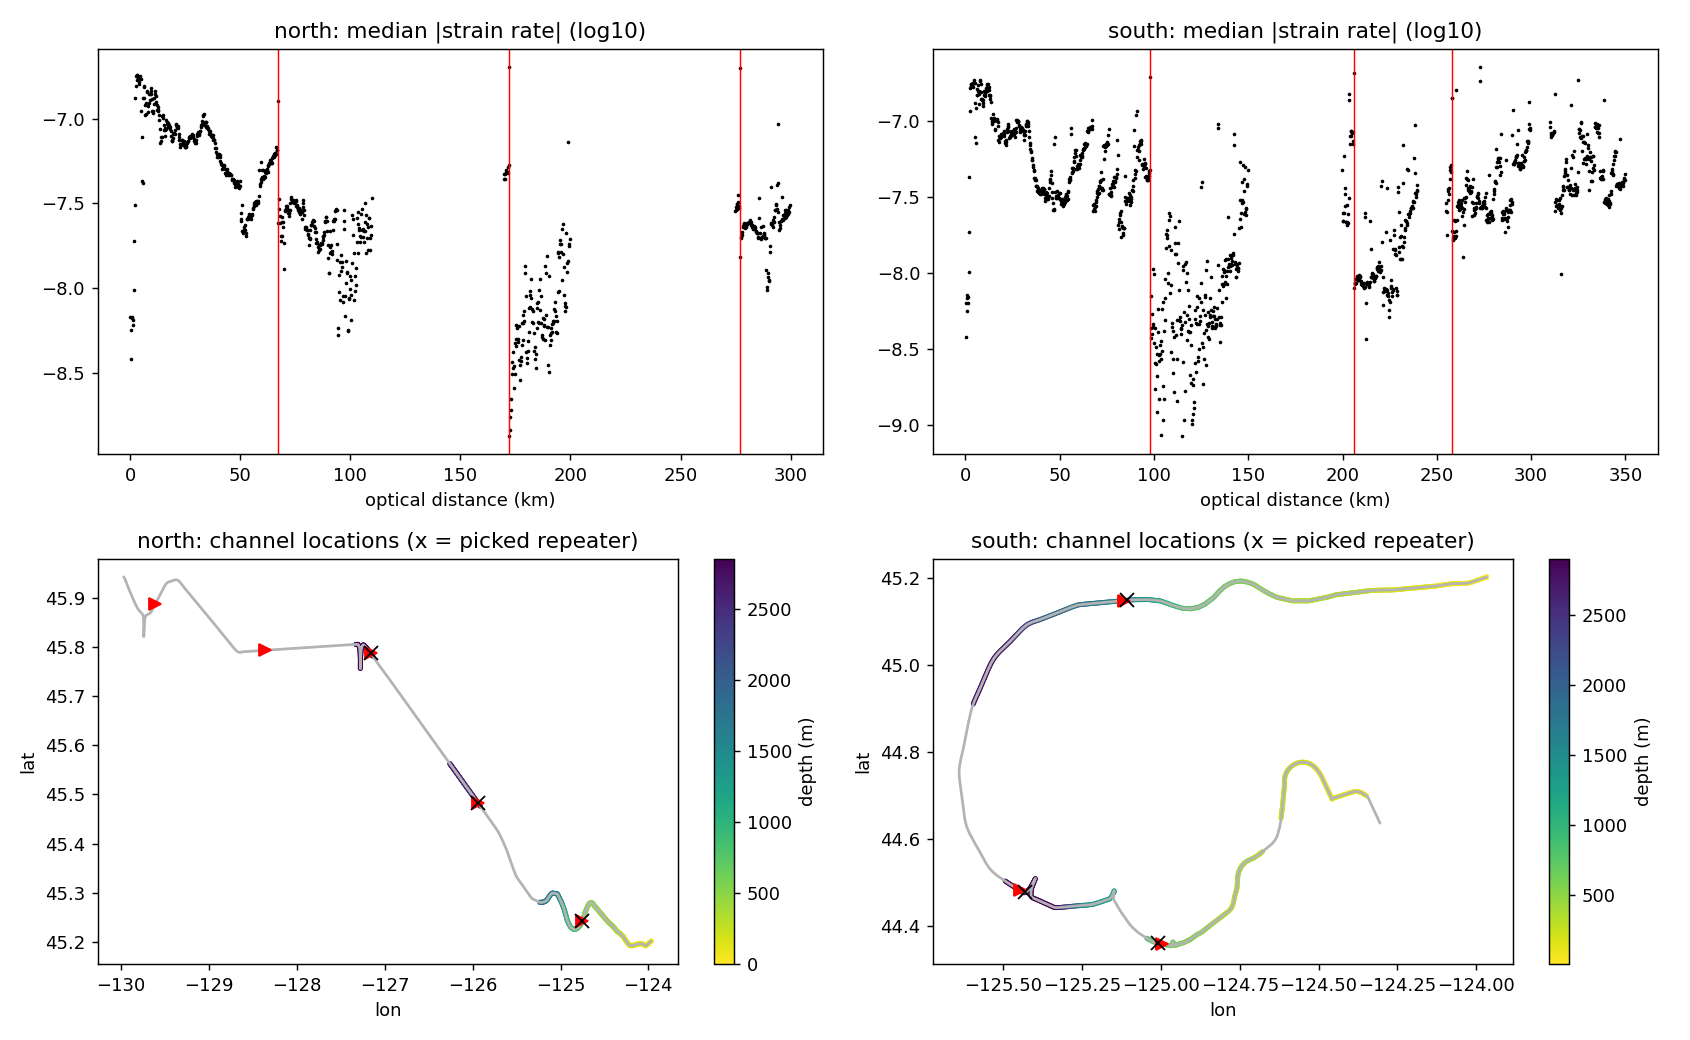

,rep_id,route_km,ch,opt_km,block,score
0,1,64.375657,317,67.113814,A,0.657853
1,2,165.616963,530,172.124703,B,2.102741
2,3,266.429025,671,276.923876,C,0.998512


,rep_id,route_km,ch,opt_km,block,score
0,1,94.679017,463,98.024277,A,1.611288
1,2,198.282566,737,205.999183,B,1.384259
2,3,252.081104,912,258.081196,C,0.910464


In [3]:
display(Image(FIG + 'geometry.png'))
for c in ('north','south'): display(pd.read_csv(f'{OUT}/repeater_picks_{c}.csv'))

In [4]:
pd.read_csv(OUT + '/events.csv')[['run','time','mag','place','dist_km','win0','win1']]

,run,time,mag,place,dist_km,win0,win1
0,N00,2026-01-16 03:25:53.034000+00:00,6.0,off the coast of Oregon,271.185790,2026-01-16 03:26:26.932223811+00:00,2026-01-16 03:49:41.508316196+00:00
1,N00,2026-01-16 06:35:03.556000+00:00,3.1,"282 km W of Bandon, Oregon",264.042933,2026-01-16 06:35:36.561366683+00:00,2026-01-16 06:38:49.173173385+00:00
2,N01,2026-01-20 06:29:50.250000+00:00,3.4,"285 km W of Bandon, Oregon",277.066501,2026-01-20 06:30:24.883312622+00:00,2026-01-20 06:33:41.076600391+00:00
3,N03,2026-01-26 23:13:56.053000+00:00,3.0,"266 km WNW of Bandon, Oregon",248.483795,2026-01-26 23:14:27.113474419+00:00,2026-01-26 23:17:35.446518142+00:00
4,N03,2026-01-26 23:19:24.801000+00:00,2.9,"258 km WNW of Bandon, Oregon",245.366010,2026-01-26 23:19:55.471751228+00:00,2026-01-26 23:23:02.947403930+00:00
5,N03,2026-01-26 23:27:00.921000+00:00,2.7,"198 km WNW of Barview, Oregon",192.236831,2026-01-26 23:27:24.950603819+00:00,2026-01-26 23:30:17.815732222+00:00
6,S00,2026-01-16 03:25:53.034000+00:00,6.0,off the coast of Oregon,271.185790,2026-01-16 03:26:26.932223811+00:00,2026-01-16 03:49:41.508316196+00:00
7,S02,2026-01-20 06:29:50.250000+00:00,3.4,"285 km W of Bandon, Oregon",277.066501,2026-01-20 06:30:24.883312622+00:00,2026-01-20 06:33:41.076600391+00:00
8,S04,2026-01-26 23:13:56.053000+00:00,3.0,"266 km WNW of Bandon, Oregon",248.483795,2026-01-26 23:14:27.113474419+00:00,2026-01-26 23:17:35.446518142+00:00
9,S04,2026-01-26 23:19:24.801000+00:00,2.9,"258 km WNW of Bandon, Oregon",245.366010,2026-01-26 23:19:55.471751228+00:00,2026-01-26 23:23:02.947403930+00:00


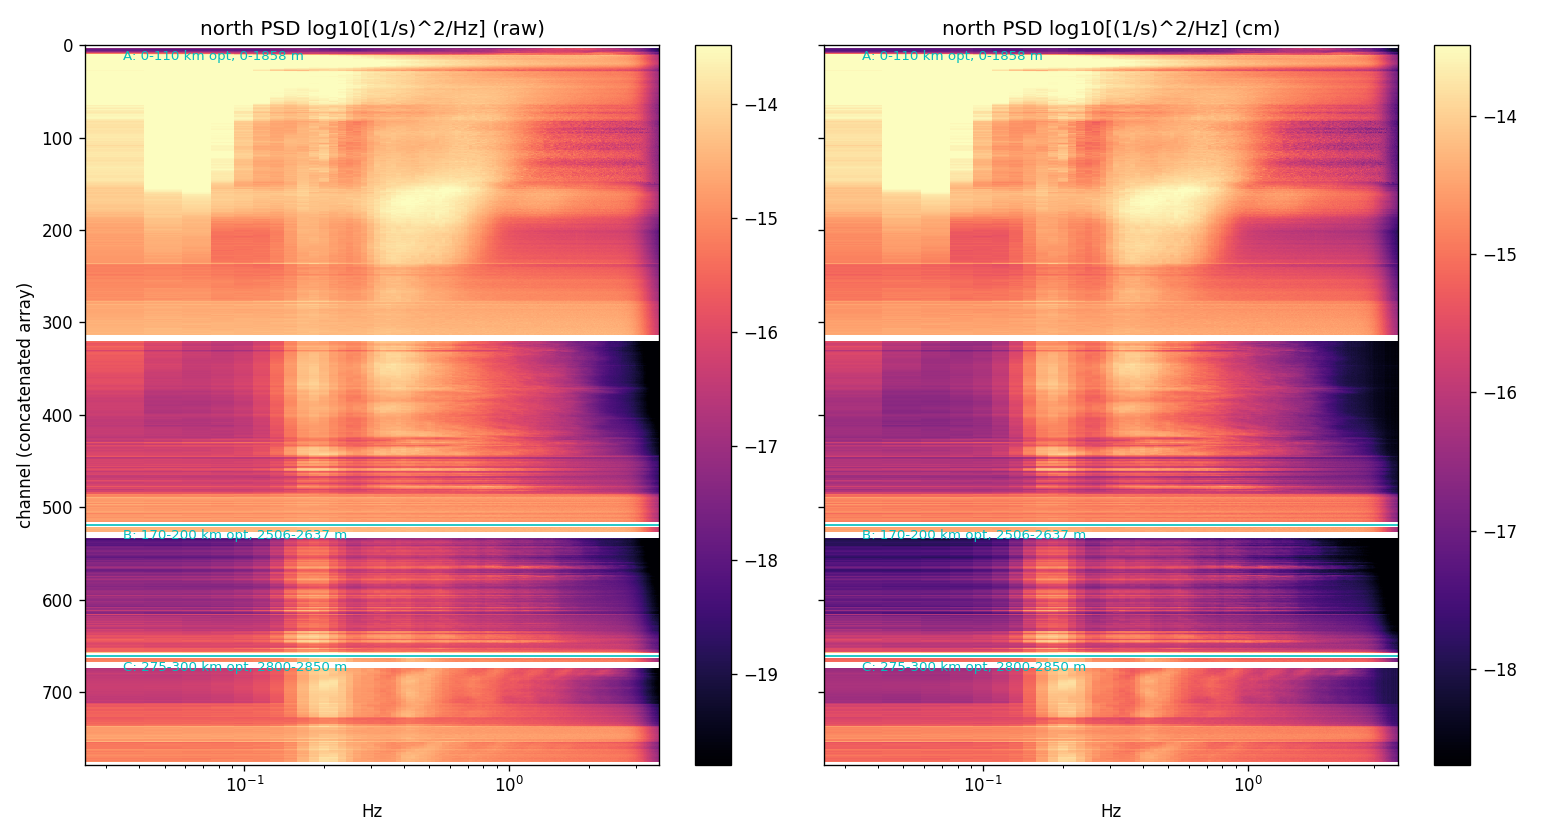

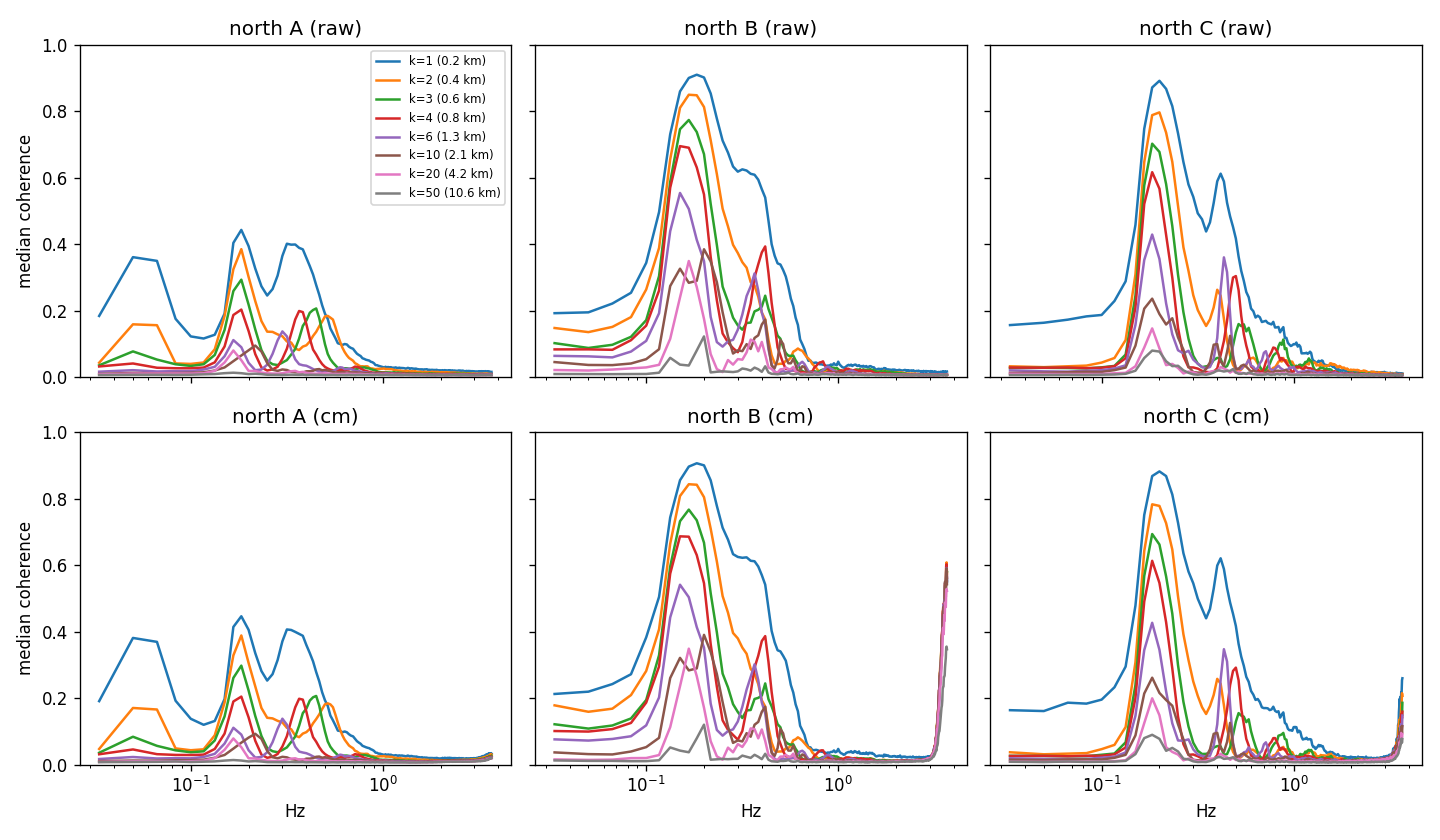

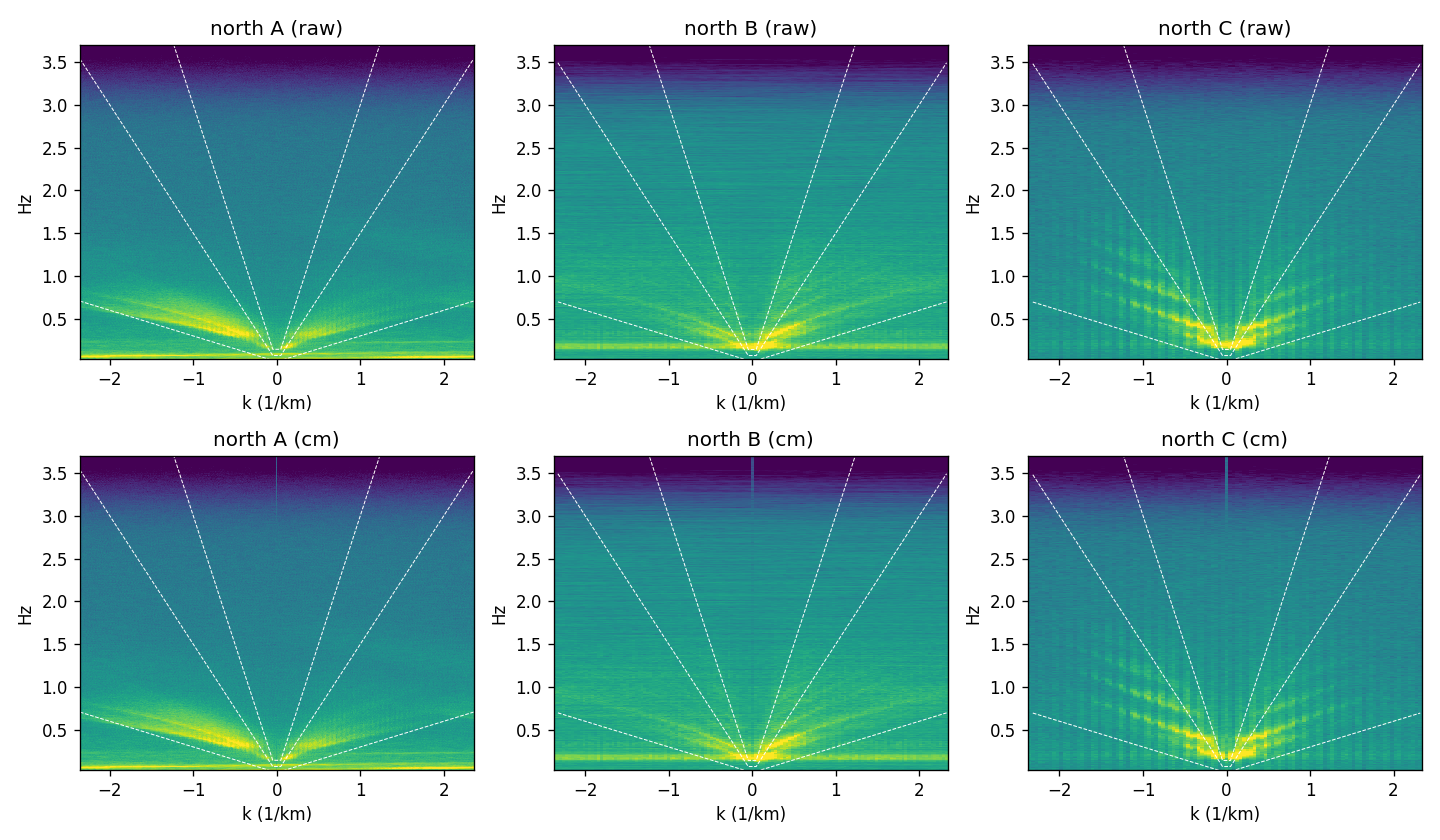

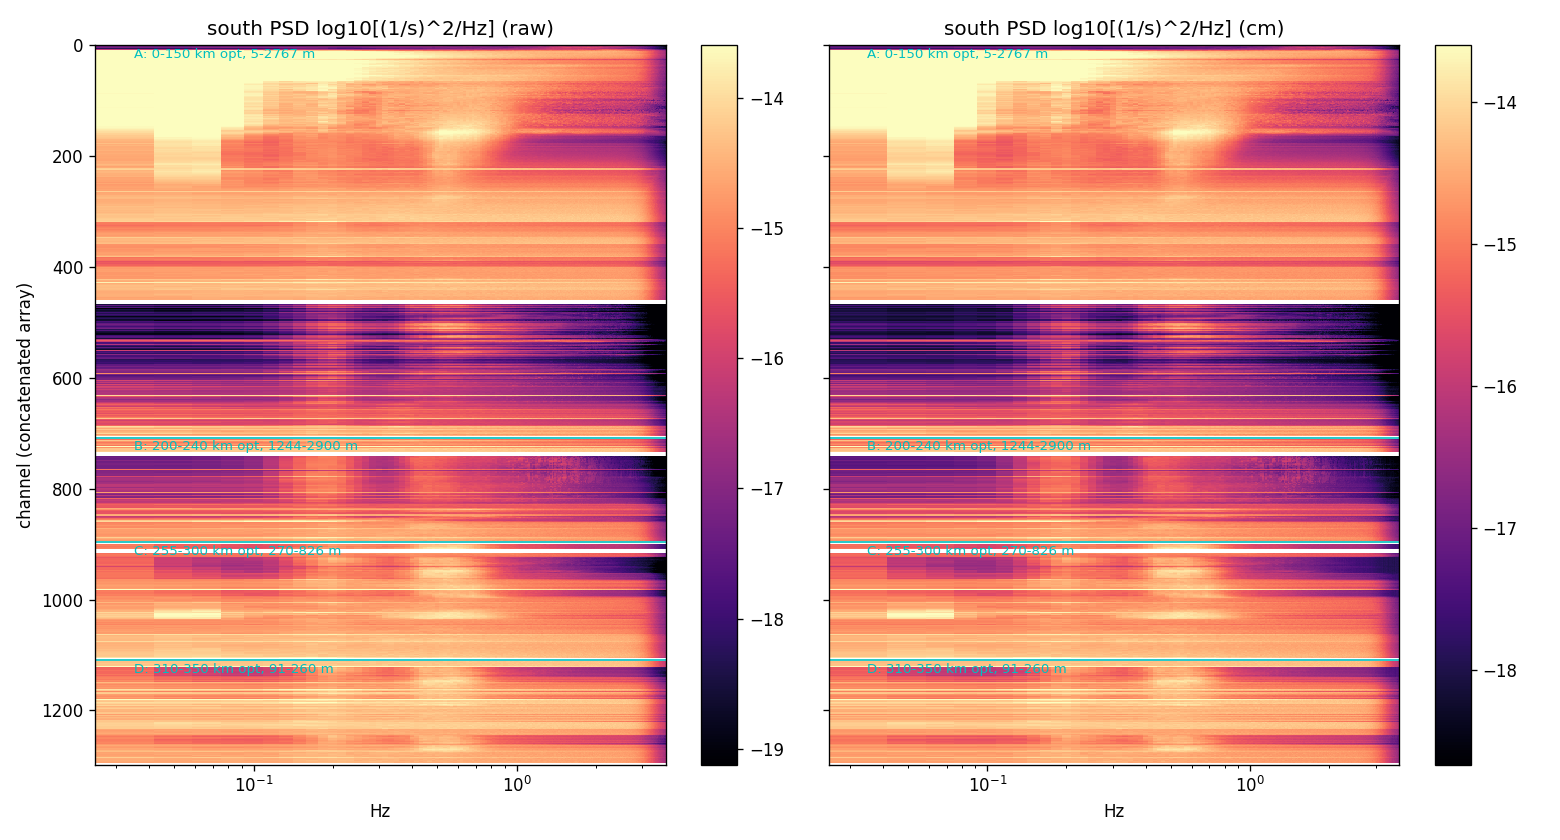

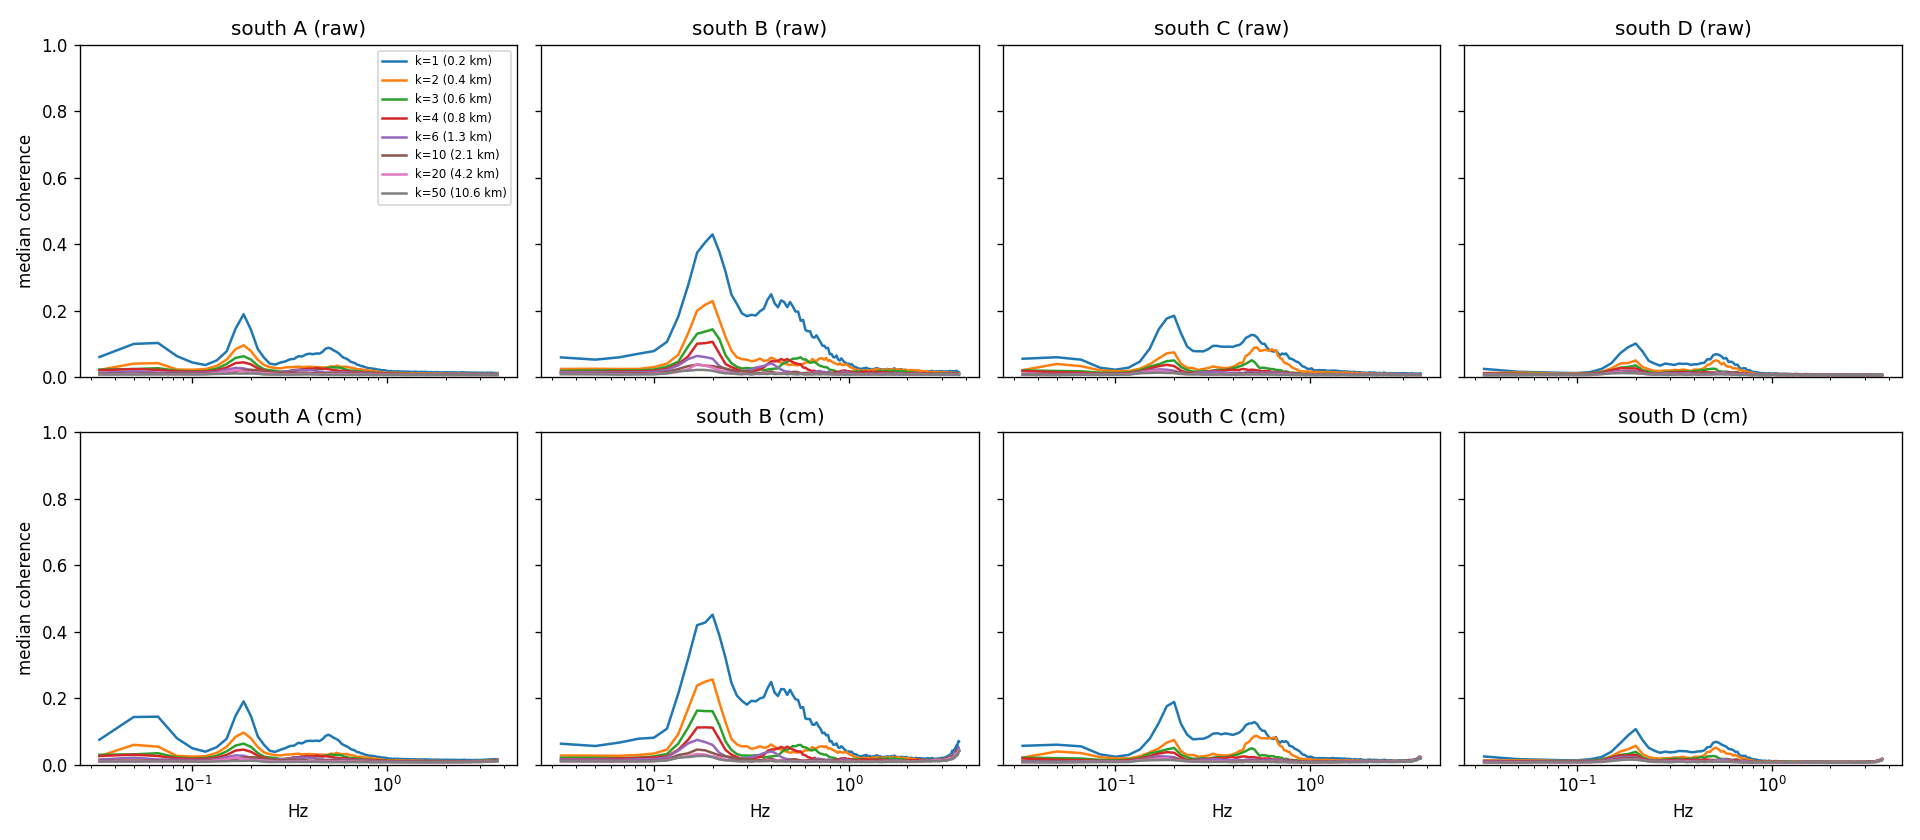

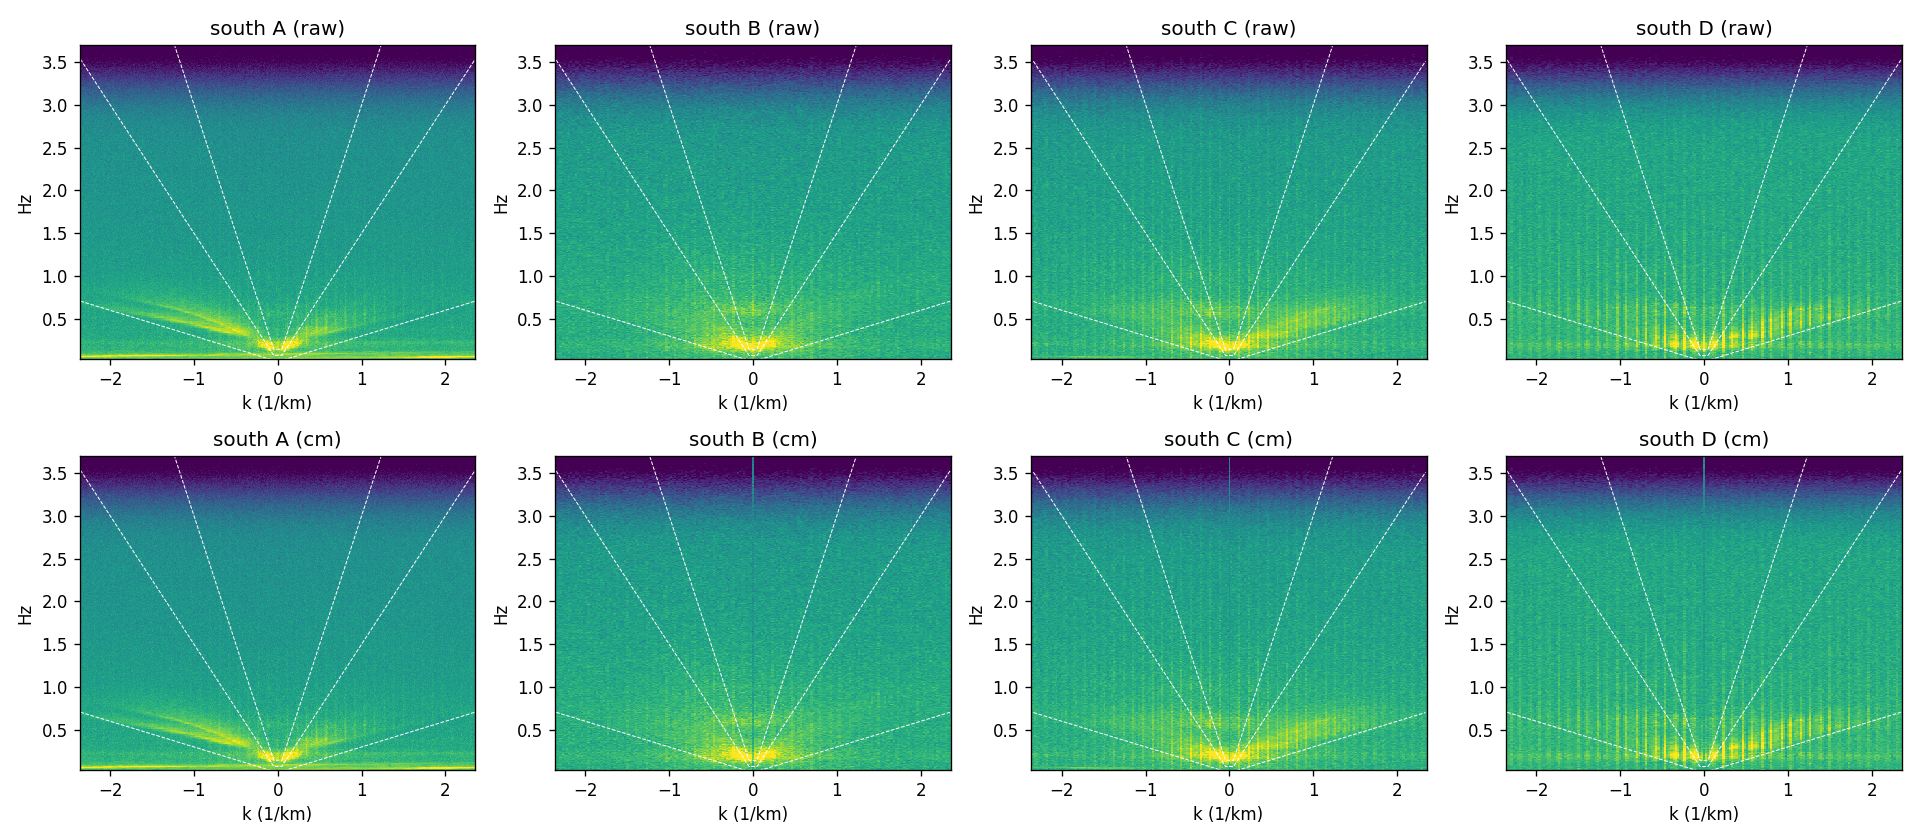

In [5]:
for c in ('north','south'):
    for k in ('psd','coherence','fk'): display(Image(f'{FIG}{k}_{c}.png'))

Channel quality: median magnitude-squared coherence at 2-channel offset (0.12–0.6 Hz). Threshold 0.15 reproduces the readme's good/bad stretches on the south cable (258–260 km bad, 261–263 and 265–268 km good, 290+ km bad).

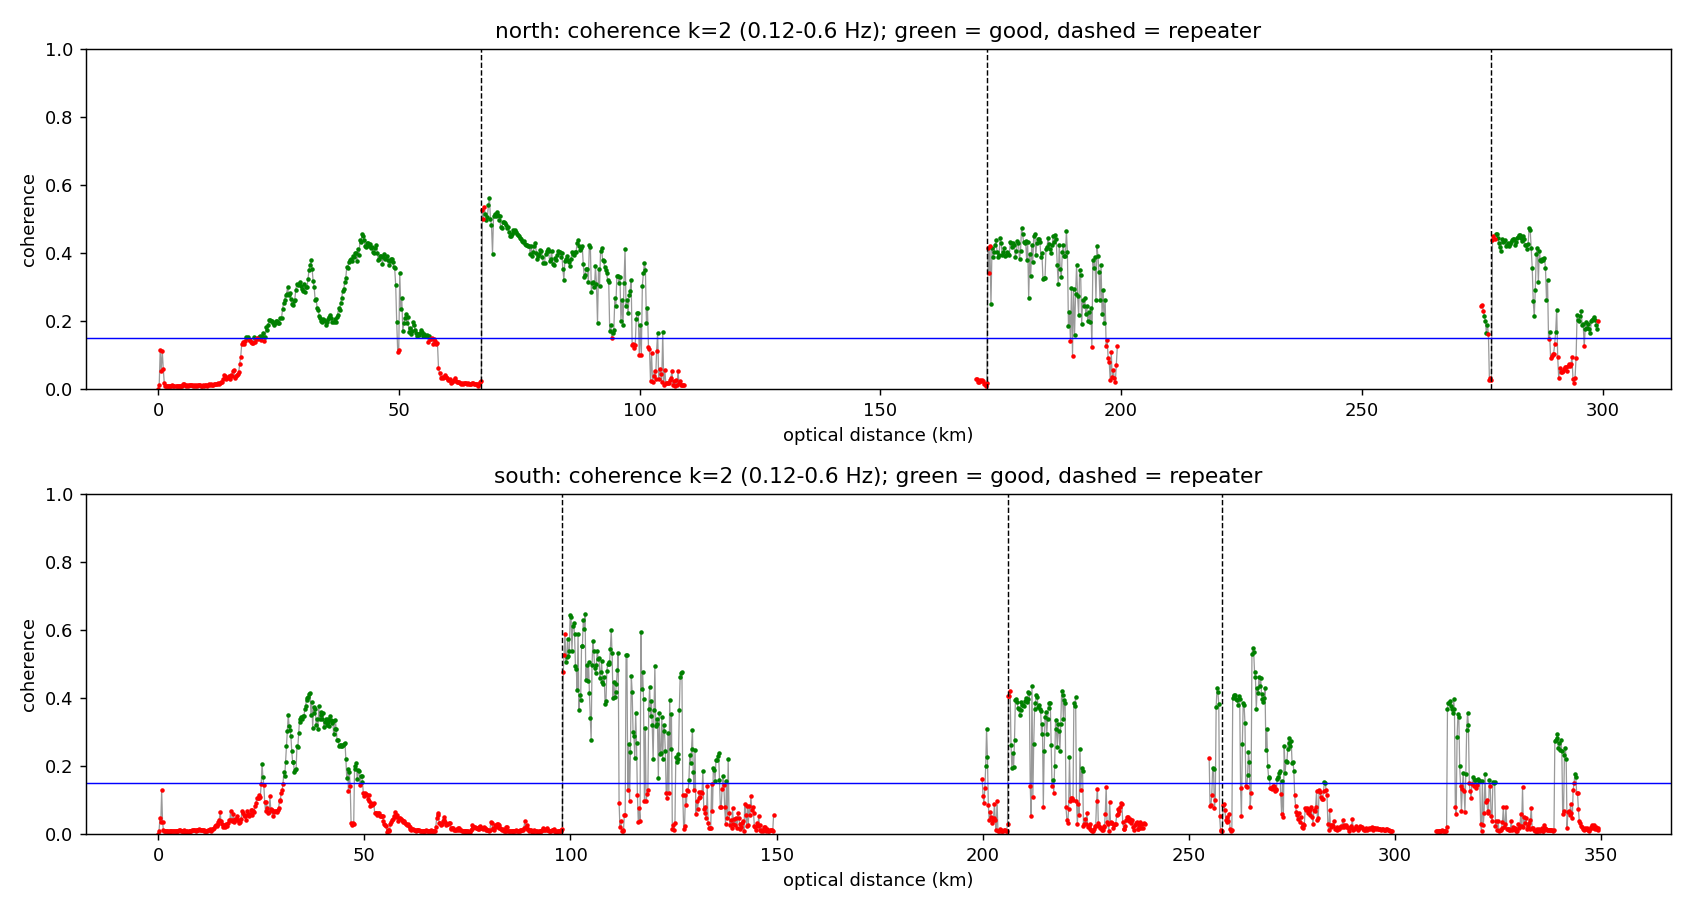

sum  size  mean
block span                 
A     1     167   317  0.53
      2     155   202  0.77
B     2       0    11  0.00
      3     110   131  0.84
C     3       4    10  0.40
      4      75   108  0.69

sum  size  mean
block span                 
A     1      86   463  0.19
      2     128   245  0.52
B     2       3    29  0.10
      3      64   160  0.40
C     3       6    15  0.40
      4      56   197  0.28
D     4      44   189  0.23

In [6]:
display(Image(FIG + 'channel_quality.png'))
for c in ('north','south'):
    q = pd.read_csv(f'{OUT}/channel_quality_{c}.csv'); display(q.groupby(['block','span']).good.agg(['sum','size','mean']).round(2))